In [5]:
from langgraph.graph import StateGraph, START, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [6]:
load_dotenv()
model = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.7
)

In [7]:
# Define state

class ChainingState(TypedDict):
    topic: str
    outline: str
    blog: str

In [8]:
def outliner(state: ChainingState) -> ChainingState:
    topic = state['topic']

    prompt = f'Make a outerline for the topic {topic}'

    state["outline"] = model.invoke(prompt).text

    return state

In [9]:
def bloger(state: ChainingState) -> ChainingState:
    outline = state["outline"]

    prompt = f'Write a comprehensive blog in accordance the following outline of the topic {outline}'

    state["blog"] = model.invoke(prompt).text

    return state

In [13]:
# Define graph
graph = StateGraph(ChainingState)

# Add nodes
graph.add_node("outliner", outliner)
graph.add_node("bloger", bloger)

# Add edges
graph.add_edge(START, "outliner")
graph.add_edge("outliner", "bloger")
graph.add_edge("bloger", END)

workflow = graph.compile()


In [ ]:
initial_state = {"topic": "Humans"}

final_state = workflow.invoke(initial_state)

print(final_state["outline"])
print(final_state["blog"])


GoogleRateLimitError: Error calling model 'gemini-3.8-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.8-flash\nPlease retry in 3h22m55.619143688s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTie

: 

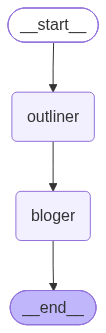

In [16]:
graph.compile()
